Complete the exercises below For **Assignment #5**.

In this exercise, we are building a logistic regression classification model. We'll work with the [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).  

Load the `tidymodels` library. 

In [1]:
# library(tidyverse)
library(tidymodels)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.13     ✔ recipes      1.3.3 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



The data is located in your homework directory in the `diabetes.csv` file. Read in the data by running the following cell. We are "splitting" the data into training and testing sets. We will evaluate our model's performance with the test set.

In [2]:
diabetes = readr::read_csv('diabetes.csv') |> mutate(Outcome = factor(Outcome))

split = initial_split(diabetes, strata = Outcome)

diabetes_train = training(split)
diabetes_test = testing(split)

Rows: 768 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, D...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Glimpse the `diabetes_train` table.

In [3]:
glimpse(diabetes_train)

Rows: 576
Columns: 9
$ Pregnancies              <dbl> 10, 4, 1, 3, 8, 1, 13, 5, 5, 6, 4, 11, 3, 7, …
$ Glucose                  <dbl> 115, 110, 103, 126, 99, 97, 145, 117, 109, 92…
$ BloodPressure            <dbl> 0, 92, 30, 88, 84, 66, 82, 92, 75, 92, 60, 76…
$ SkinThickness            <dbl> 0, 0, 38, 41, 0, 15, 19, 0, 26, 0, 33, 0, 25,…
$ Insulin                  <dbl> 0, 0, 83, 235, 0, 140, 110, 0, 0, 0, 192, 0, …
$ BMI                      <dbl> 35.3, 37.6, 43.3, 39.3, 35.4, 23.2, 22.2, 34.…
$ DiabetesPedigreeFunction <dbl> 0.134, 0.191, 0.183, 0.704, 0.388, 0.487, 0.2…
$ Age                      <dbl> 29, 30, 33, 27, 50, 22, 57, 38, 60, 28, 33, 3…
$ Outcome                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


❓ Which variable is suitable as the "outcome" in a logistic regression model?

**Answer:**

outcomes

❓ Navigate to [Kaggle page](https://www.kaggle.com/datasets/mathchi/diabetes-data-set) for this dataset. Find descriptions for the `Glucose` and `BMI` columns. Add these descriptions to the [Markdown table](https://www.markdownguide.org/extended-syntax/#tables) below.

| Column name | Description |
| :---------- | :---------- |
| Glucose     |    plasma gelcouse concentration 2 hours before         |
| BMI         |    body mass index claculate weight diveded by hight       |

Make a bar chart showing the frequency of each "outcome" in the `Outcome` column from your `diabetes_train` data.

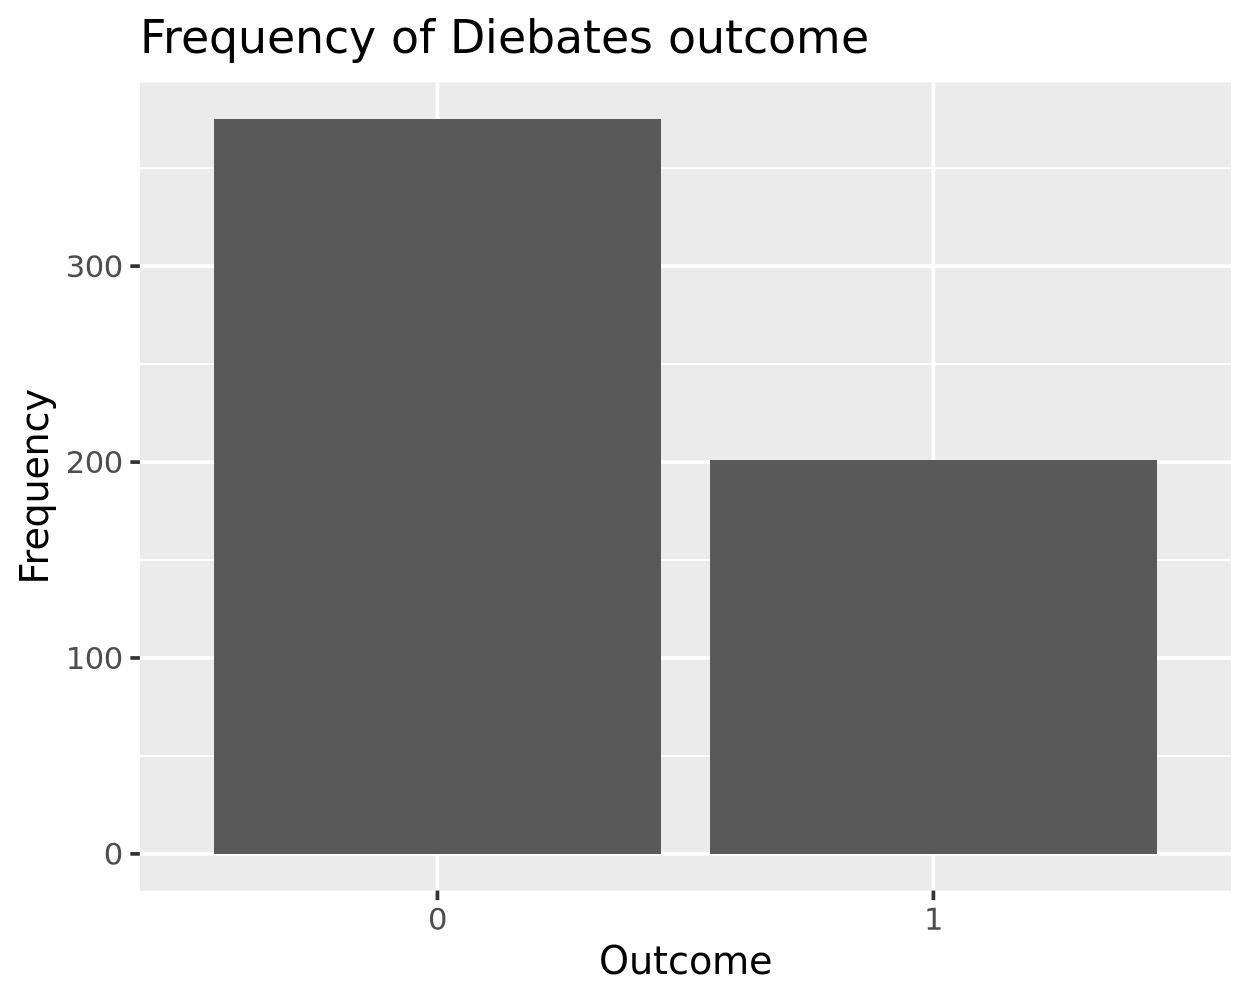

In [4]:


ggplot(diabetes_train, aes(x = Outcome))+
geom_bar()+
labs(
    title = "Frequency of Diebates outcome",
    x = "Outcome",
    y = "Frequency"
    )


❓ Is the data balanced? I.e. do we have equal counts of each outcome?

**Answer:**


No the outcome is not balanced the number of no debeties(=0) is greter than the number of debeties (=1)so the two class have unbalanced or unequal counts. 


Run the code below to create a table for plotting the predictors we will use in our model: `Glucose` and `BMI`. 

In [5]:
plot_df = diabetes_train |>
    select(Outcome, Glucose, BMI) |>
    pivot_longer(cols = c(Glucose, BMI))

plot_df |> head()

Outcome,name,value
<fct>,<chr>,<dbl>
0,Glucose,115.0
0,BMI,35.3
0,Glucose,110.0
0,BMI,37.6
0,Glucose,103.0
0,BMI,43.3


Using `plot_df`, make a chart showing the relationship of `Glucose` and `BMI` with `Outcome`. 

- use `geom_jitter` for your "geom"
- `facet_wrap` your chart by the `name` variable. (e.g. `facet_wrap(~name, ncol = 2, scales = 'free_x')`)

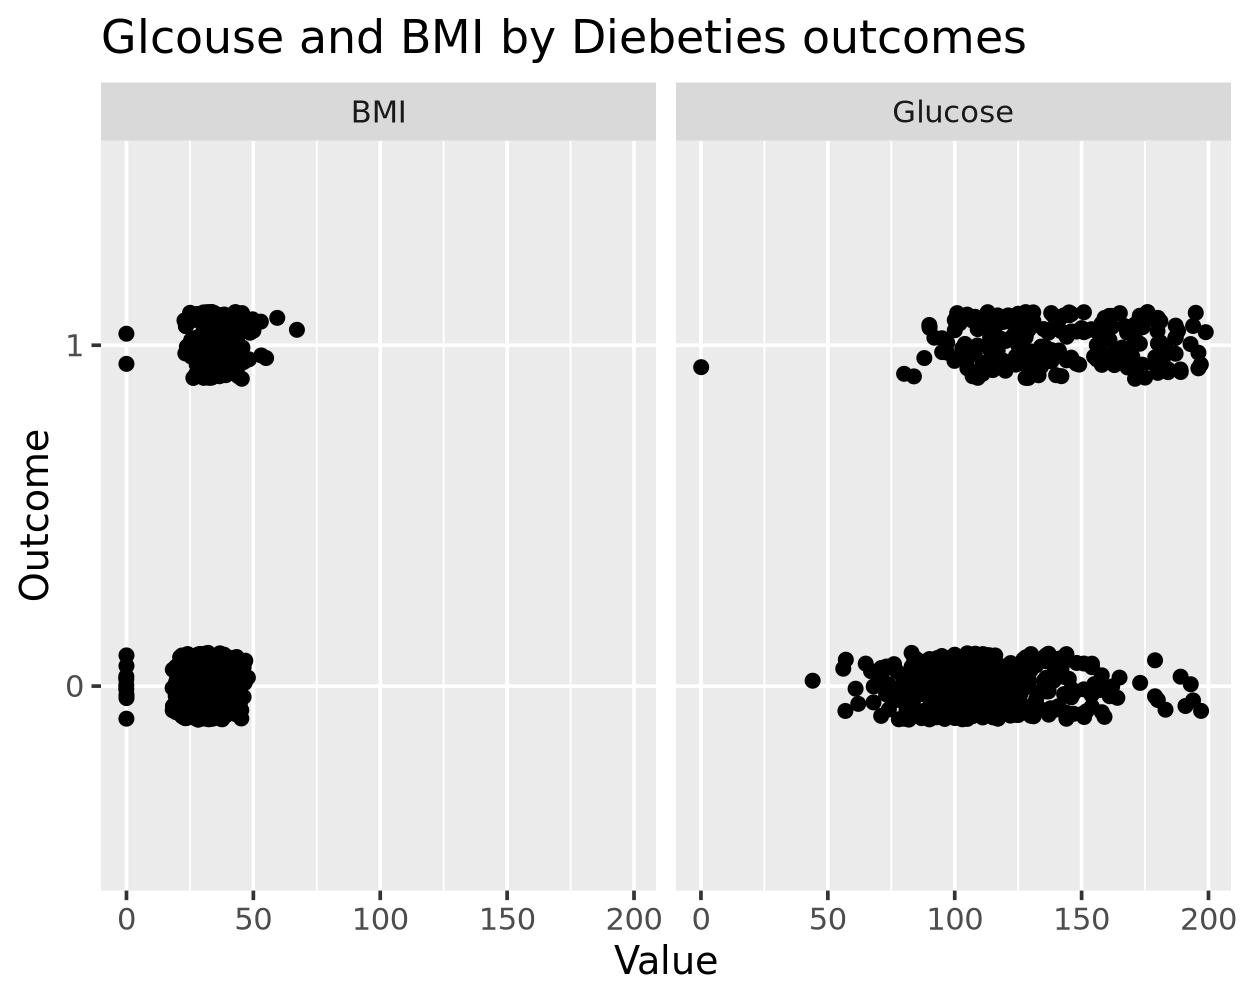

In [6]:
ggplot(plot_df, aes(x = value, y = Outcome))+
geom_jitter(height=0.1, width = 0.1)+
facet_wrap(~name, ncol = 2)+
labs(
    title = "Glcouse and BMI by Diebeties outcomes",
    x = "Value",
    y = "Outcome"
    )

❓ What happens when you remove the `scales = 'free_x'` argument from the `facet_wrap` function?

**Answer:**

when i removed the scales in the BMI the value moved to in beteween 0 and 50 while Glucose does not have that much shifting. 

Using your training data, build logistic regression model of `Outcome` with `BMI` and `Glucose` as predictors. 
- Use "glm" for you engine
- The formula for your fit function will be `Outcome ~ BMI + Glucose`

In [7]:
logistic_model <- glm(
    Outcome ~ BMI + Glucose,
    data = diabetes_train,
    family = binomial
    )
# i just add the head(1) to see how the model look like 
logistic_model |> head(1)

$coefficients
(Intercept)         BMI     Glucose 
-7.39178974  0.07742016  0.03409928

Using `augment` with your fitted model and the `diabetes_test` data as arguments, create a new dataset called `diabetes_test_wPred` that is the `diabetes_test` table including predictions from your model. 

In [8]:
diabetes_test_wPred <- augment( 
    logistic_model,
    newdata = diabetes_test,
    type.predict = "response"
    )

diabetes_test_wPred |> head()

Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,.fitted
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>
1,85,66,29,0,26.6,0.351,31,0,0.08061835
1,89,66,23,94,28.1,0.167,21,0,0.10142891
5,116,74,0,0,25.6,0.201,30,0,0.18933797
3,78,50,32,88,31.0,0.248,26,1,0.08850547
2,197,70,45,543,30.5,0.158,53,1,0.84384010
10,139,80,0,0,27.1,1.441,57,0,0.36495912


In [14]:
diabetes_test_wPred = augment(mod_fit, new_data = diabetes_test)

diabetes_test_wPred |> conf_mat(Outcome, .pred_class) 

ERROR: Error: object 'mod_fit' not found


Run the code below to generate a confusion matrix for your model predictions. 

(❗️Hint: See Table 4.4 from [*Introduction to Statistical Learning (Version 2)*](https://www.statlearning.com/) for an example confusion matrix.)

❓ Based on the confusion matrix above, 
- How many individuals had diabetes in your test data?
- Of those that actually had diabetes, how many were predicted to have diabetes by your model?
- How many individuals predicted to have diabetes did not have diabetes?

**Answer:**